## Анализ данных о Нобелевских лауреатах

### **Контекст проекта**
В этом задании мы будем работать с датасетом о лауреатах Нобелевской премии. Ваша задача — распарсить и проанализировать эти данные, ответив на ключевые вопросы о закономерностях вручения премий, демографических характеристиках лауреатов и исторических тенденциях.

### **Этап 1: Подготовка данных**

**Задача:** На этом этапе вам надо собрать структурированный список словарей с информацией о лауреатах и призах. Приведем начало нужного нам датасета.

``` {code:python}
[{'id': '745',
  'name': 'A. Michael Spence',
  'gender': 'male',
  'birth_year': 1943,
  'country_birth': 'USA',
  'country_now': 'USA',
  'prizes_relevant': [{'prize_amount': 10000000,
    'prize_amount_adjusted': 15547541,
    'award_year': 2001,
    'category_en': 'Economic Sciences',
    'prize_status': 'received'}],
  'type_': 'person'},
 {'id': '102',
  'name': 'Aage N. Bohr',
  'gender': 'male',
  'birth_year': 1922,
  'country_birth': 'Denmark',
  'country_now': 'Denmark',
  'prizes_relevant': [{'prize_amount': 630000,
    'prize_amount_adjusted': 4304697,
    'award_year': 1975,
    'category_en': 'Physics',
    'prize_status': 'received'}],
  'type_': 'person'}]
  ```

Поскольку информация о лауреатах-людях и лауреатах-организациях структурирована по-разному, а также из-за того, что часть полей в json могут отсутстввовать, необходимо реализовать функции для процессинга словарей, которые будут достаточно обобщаемыми для обоих типов данных.

**Что нужно сделать:**

На входе информация о конкретном лауреате представляет из себя кучу вложенных друг в друга словарей. Из этой структуры нам надо получить плоский словарь вида {atribute: value}, где atribute --- это один из небольшого множества интересных нам атрибутов. При этом в исходном файле 
1. пути к атрибутам могут иметь разную длину
2. атрибуты могут отсутствовать
3. атрибуты могут нуждаться в дополнительной обработке (например, поле id в исходных словарях записано как строка.)

Поскольку наивная реализация такого обработчика оказывается довольно громоздкой, вам нужно создать файл json_dict_processing.py, в котором реализован высокоуровневый функционал для решения задачи "обработать вложенный json-словарь"

Главное требование к интерфейсу: 
по (вложенному) словарю о лауреате и конфигу (см ниже) надо получить плоский словарь вида {atribute: value}.

Достичь этого можно, например, таким набором функций

* `extract_nested_value(obj, keys)` - извлекает значение из вложенных структур данных по цепочке ключей

* `process_dictionary_with_config(dictionary, config)` - обрабатывает один словарь согласно словару-конфигу (формат конфига см ниже.)

* `process_list_of_dicts_with_config(list_of_dicts, config)` - обрабатывает список словарей, эта функция нужна чтобы обработать список призов.

* `create_processor(config, list_processor=False)` - создает готовый процессор с предзагруженной конфигурацией. В случае, если list_processor == True, внутрь процессора подается process_list_of_dicts_with_config, иначе process_dictionary_with_config.

**Замечание насчет последней функции.**

Планируемое применение этой функции примерно такое:
`laureate_processor = create_processor(PERSON_CONFIG, list_processor=False)`

То есть, create_processor возвращает функцию, которая реализует функционал process_dictionary_with_config но с уже заполненным конфигом. Это повышает читаемость кода и снижает риск перепутать конфиги из-за дублирования кода.


Помимо этого нужно создать файлы-конфиги для данных по призам, лауреатам-людям, и лауреатам-организациям.

КОНФИГ для функций process_dictionary_with_config и process_list_of_dicts_with_config имеет следующий вид
```python
  {'атрибут_который_берем_сырым': ['путь', 'к', 'данным'],  # или
  'атрибут_который_нужно_обработать': (['путь', 'к', 'данным'], функция_обработки)}
  ```
В случае, если атрибут можно взять в итоговый датасет сырым, в values() словаря-конфига будет список path_list.
Если же атрибут еще надо обработать, для него в поле config[attribute] будет tuple вида (path_list, function).

Примеры атрибутов, которые можно взять сырыми: имя, размер приза. Примеры атрибутов, которые нужно обработать: год вручения приза (в сырых данных есть только полная дата, записанная как строка)

После того, как будет создан core.py, создайте конфиги laureates_configs.py и prizes_configs.py

Постарайтесь провалидировать код с помощью assert-ов, вызываемых в ноутбуке или в .py-файлах.

пример использования: 

assert 1 == True

**Валидация**

В вашем случае assert должен взять простой словарик с одним вложенным полем и какой-нибудь конфиг-файл.
Также убедитесь, что при обработке данных собственно по лауреатам в них нет странностей (смотрите ниже) 

**Атрибуты для ПРИЗА (CONFIG_PRIZE, prizes_configs.py)**

- `prize_amount` - сумма приза → `prizeAmount`
- `prize_amount_adjusted` - скорректированная сумма приза → `prizeAmountAdjusted`
- `award_year` - год вручения приза (преобразуется в целое число) → `awardYear`
- `category_en` - категория на английском → `category.en`
- `prize_status` - статус приза → `prizeStatus`

**Атрибуты для ЧЕЛОВЕКА-ЛАУРЕАТА (CONFIG_PERSON, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - имя лауреата → `knownName.en`
- `gender` - пол → `gender`
- `birth_year` - год рождения (извлекается из даты) → `birth.date`
- `country_birth` - страна рождения → `birth.place.country.en`
- `country_now` - текущая страна → `birth.place.countryNow.en`
- `prizes_relevant` - список призов лауреата → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Атрибуты для ОРГАНИЗАЦИИ-ЛАУРЕАТА (CONFIG_ORG, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - название организации → `orgName.en`
- `founded_year` - год основания (извлекается из даты) → `founded.date`
- `country_founded` - страна основания → `founded.place.country.en`
- `country_now` - текущая страна → `founded.place.countryNow.en`
- `prizes_relevant` - список призов организации → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Вспомогательные функции:**

- `process_year(year_string)` - извлекает год из строки даты (формат "YYYY-MM-DD"). Функция находится в файле laureates_configs.py
- `prize_processor()` - создает процессор для обработки списков призов. Функция находится в файле prizes_configs.py
- `person_processor()` - создает процессор для данных о людях-лауреатах. Функция находится в файле laureates_configs.py
- `org_processor()` - создает процессор для данных об организациях-лауреатах. Функция находится в файле laureates_configs.py

In [1]:
import requests
from preparing_data.laureates_configs import person_processor, org_processor

URL_LAUREATES = 'https://api.nobelprize.org/2.1/laureates?limit=1200'

laureates_response = requests.get(URL_LAUREATES)
headers = {'User-Agent': 'Mozilla/5.0'}
laureates_response = requests.get(URL_LAUREATES, headers=headers)
raw_laureates = laureates_response.json()['laureates']

# у людей есть knownName, у организаций - orgName
person_proc, org_proc = person_processor(), org_processor()
laureates_data = [
    person_proc(item) if 'knownName' in item else org_proc(item)
    for item in raw_laureates
]



In [2]:
from preparing_data.laureates_configs import process_orgs, process_persons  # реализуйте эти функции согласно описанной выше логике

def get_laureate_data(laureate):
    """
    Определите тип лауреата and соотв образом обработайте данных.
    
    Args:
        laureate: Dictionary with laureate data
        
    Returns:
        Processed laureate data with added 'type_' field ('person' or 'org')
        
    Determines type by:
    - 'knownName' key → person (uses process_persons)
    - 'orgName' key → org (uses process_orgs)
    """
    # YOUR CODE HERE
    """Определяет тип лауреата, обрабатывает его и добавляет поле 'type_'."""
    if 'knownName' in laureate:
        result = process_persons(laureate)
        result['type_'] = 'person'
    elif 'orgName' in laureate:
        result = process_orgs(laureate)
        result['type_'] = 'org'
    else:
        raise ValueError(f"Неизвестный тип лауреата: id={laureate.get('id')}")
    return result


laureates_data = []
for laureate in raw_laureates:
    laureates_data.append(get_laureate_data(laureate))



### **Этап 2: EDA лауреатов**

EDA или Exploratory Data Analysis - первый шаг при работе с любыми данными.

Чтобы начать работать с этой секцией, проведите проведите чисто технический анализ собранных данных.

1. Сколько всего записей?
2. Все ли значения полей заполнены?
3. Если нет, сколько пропусков в каждом из полей? Выведите ответ на этот вопрос в формате `{'field_name': missing_values}`. А какая доля пропусков?
5. Каковы максимальные и минимальные значения поля id и каким годам награждения они соответствуют? Есть ли записи с повторяющимися id? Есть ли пары айди, которые в отсортированном массиве айдишников различаются более, чем на один? 

При реализации ответов на эти вопросы, пользуйтесь теми же принципами, что описаны выше. Можете начать с плохого хакерского кода, однако в таком случае в маркдауне пропишите, как будете его обобщать и разносить по функциям и модулям. (об этом ниже)

В основном EDA пользуйтесь аккуратным кодом, разбитым на функции и файлы.

In [3]:
from preparing_data.eda import (
    count_missing, get_missing_share, find_min_max_id,
    find_duplicate_ids, find_id_gaps,
)

total = len(laureates_data)
missing = count_missing(laureates_data)

print('Всего записей:', total)
print('Пропуски:', missing)
print('Доля пропусков:', get_missing_share(missing, total))
print('Min и max id:', find_min_max_id(laureates_data))
print('Дубликаты id:', find_duplicate_ids(laureates_data))
print('Разрывы в id:', find_id_gaps(laureates_data))

Всего записей: 1028
Пропуски: {'founded_year': 1001, 'country_founded': 1004, 'id': 0, 'birth_year': 28, 'prizes_relevant': 0, 'type_': 0, 'gender': 28, 'country_now': 7, 'name': 0, 'country_birth': 31}
Доля пропусков: {'founded_year': 0.974, 'country_founded': 0.977, 'id': 0.0, 'birth_year': 0.027, 'prizes_relevant': 0.0, 'type_': 0.0, 'gender': 0.027, 'country_now': 0.007, 'name': 0.0, 'country_birth': 0.03}
Min и max id: {'min_id': 1, 'min_id_years': [1901], 'max_id': 1070, 'max_id_years': [2026]}
Дубликаты id: []
Разрывы в id: [(6, 8), (93, 95), (169, 172), (255, 257), (468, 470), (503, 505), (520, 523), (541, 543), (569, 571), (590, 592), (594, 596), (597, 600), (610, 613), (615, 617), (631, 633), (635, 637), (645, 647), (655, 657), (783, 786), (787, 789), (858, 861), (896, 903), (949, 958), (1009, 1011)]



Поскольку это курс по Python, а не по статистике или визуализации данных, мы не задаем жесткие рамки того, что вы должны проанализировать.
Однако это отличная возможность представить себя в роли разработчика базы данных или, например, библиотеки pandas.

В коде нужно соблюдать следующие правила:

1. должны быть реализованы  несколько способов работы с данными (среднее/медианное/максимальное значение метрики, количество примеров, вывод топ-N объектов по значению метрики).
2. анализ выбранных вами тем должен включать в себя анализ метрик в тотале, по категориям и в динамике по годам или десятилетиям.
3. проанализировать стоит 2-3 темы. Вы можете использовать темы ниже или взять свои.
2. вывод ноутбука должен быть понятен обывателю. Это может быть визуализация в matplotlib/seaborn. Сопровождайте вывод markdown-ячейками с вашими  мыслями, пояснениями и инсайтами, которые удалось извлечь.
3. Нельзя использовать pandas и numpy, но можно вдохновляться их интерфейсом и функционалом при дизайне ваших функций.


Из пункта 2 следует, что вам придется работать не только с атрибутами лауреатов, но и самих призов.
Информацию о призах нужно доставать и записывать как атрибут уже лауреата. Функции, работающие с призами (например, факт того, что лауреат отказался от какого-то из призов) можно реализовать в ноутбуке, но если вы создаете более общие вспомогательные функции, выносите их в отдельные модули.

Мы рекомендуем следующую структуру кода:

* `dataset_helpers.py` в котором реализованы фильтрация списка словарей (плоских) по условиям (аналог sql-ного where), а также аналог sql-ного групбая. А также функция для применения агрегаций к списку словарей
* `aggregations.py` в котором реализованы функции расчета среднего/медианы/других эвристик и мб вывод топ n-значений по какой-то метрике.
* `atribute_manager.py` в котором реализован переиспользуемый интерфейс для добавления (и мб удаления) полей.

Замечание насчет group-by. 

На игрушесном примере она может работать примерно так:
```
    Входные данные: [
        {'name': 'Alice', 'country': 'USA', 'age': 25},
        {'name': 'Bob', 'country': 'UK', 'age': 30},
        {'name': 'Charlie', 'country': 'USA', 'age': 25}
    ]
    
    group_by_attributes(data, ['country', 'age']) → {
        ('USA', 25): [
            {'name': 'Alice', 'country': 'USA', 'age': 25},
            {'name': 'Charlie', 'country': 'USA', 'age': 25}
        ],
        ('UK', 30): [
            {'name': 'Bob', 'country': 'UK', 'age': 30}
        ]
    }
```

Замечание насчет agregations.py
1. Агрегации соответственно должны применяться к спискам вида [
    {'name': 'Alice', 'country': 'USA', 'age': 25},
    {'name': 'Charlie', 'country': 'USA', 'age': 25}
]
2. Пользуйтесь модулем statistics из стандартной библиотеки питона.


Эта структура одна из возможных для организации вашего кода, главное, чтобы эти достаточно общие функции блыи переиспользованы

----------

При анализе данных вам понадобятся более конкретные функции, например filter_by_num_prizes или output_metric_by_category. Их пишите прямо в ноутбуке и сопровождайте коментами.

Ниже мы приводим некоторые примеры вопросов, которые может быть интересно задать к данным, но если у вас есть желание, можете поисследовать датасет с любой интересной вам стороны!


**2.1. Топ-статистика по странам**
- Определите топ-5 стран по общему количеству лауреатов
- Постройте аналогичные рейтинги отдельно по категориям (физика, химия, медицина и т.д.)

**2.2. Возраст при награждении**
- Рассчитать средний возраст лауреатов на момент получения **первого** приза. Рассмотрите только лауреатов-людей.
- Исследуйте, как средний возраст получения первого приза различается по категориям
- Различаются ли средний и медианный возрасты? 

**2.3. Гендерное распределение**
- Как менялось количество женщин-лауреатов по десятилетиям?
- Сравните распределение лауреаток по категориям. Выведите значения суммарно за все годы и по декадам.
- В какой из категорий больше всего женщин лауреаток изначально и в последние пару десятилетий?

**2.4. Миграции лауреатов**
- У скольки лауреатов исходная страна и страна на момент вручения нобелевской премии различаются? Всегда ли это различие объясняется миграцией? Добавьте вспомогательное поле 'country_of_origin_adjusted_for_migration', чтобы различие между этим полем и страной на момент вручения объяснялось миграцией.
- Выявите страны с наибольшей долей "оттекших" и "притекших" лауреатов.
- Есть ли оттоки среди организаций?

**2.5. Многократные лауреаты**
- Найдите лауреатов, получившие больше одного приза. Кто получил больше 2 раз? 
- Совпадает ли категория второго приза с первой?  
- Сколько в среднем времени прошло между получением первой и второй премии?

**2.6 Отказы от премий**
- Определите, в каких категориях чаще отказывались от премий?
- Есть ли отказы среди организаций?

In [4]:
from typing import Any
from preparing_data.attribute_manager import add_attribute


def get_first_prize(record: dict) -> dict | None:
    """Возвращает самый ранний приз лауреата (по award_year).

    Принимает: record - словарь одного лауреата.
    Возвращает: словарь приза или None, если призов или годов нет.
    """
    prizes = record.get('prizes_relevant') or []
    # беру только призы, где год известен, иначе min упадёт на None
    prizes_with_year = [prize for prize in prizes if prize.get('award_year') is not None]
    if not prizes_with_year:
        return None
    return min(prizes_with_year, key=lambda prize: prize['award_year'])


def get_first_prize_year(record: dict) -> int | None:
    """Год первого приза или None."""
    first_prize = get_first_prize(record)
    return first_prize['award_year'] if first_prize else None


def get_first_prize_category(record: dict) -> str | None:
    """Категория первого приза или None."""
    first_prize = get_first_prize(record)
    return first_prize.get('category_en') if first_prize else None


def get_age_at_first_prize(record: dict) -> int | None:
    """Возраст на момент первого приза (только для людей, у организаций будет None)."""
    first_year = record.get('first_prize_year')
    birth_year = record.get('birth_year')
    if first_year is None or birth_year is None:
        return None
    return first_year - birth_year


def get_first_prize_decade(record: dict) -> int | None:
    """Десятилетие первого приза, например 1987 -> 1980."""
    first_year = record.get('first_prize_year')
    if first_year is None:
        return None
    return first_year // 10 * 10


def get_prizes_count(record: dict) -> int:
    """Количество призов лауреата."""
    return len(record.get('prizes_relevant') or [])


# порядок важен: age и decade используют уже добавленное first_prize_year
add_attribute(laureates_data, 'first_prize_year', get_first_prize_year)
add_attribute(laureates_data, 'first_prize_category', get_first_prize_category)
add_attribute(laureates_data, 'age_at_first_prize', get_age_at_first_prize)
add_attribute(laureates_data, 'first_prize_decade', get_first_prize_decade)
add_attribute(laureates_data, 'prizes_count', get_prizes_count)

assert laureates_data[0]['first_prize_year'] is not None

[(('USA',), 306), (('United Kingdom',), 96), (('Germany',), 86), (('France',), 66), (('Japan',), 32)]
Economic Sciences [('USA', 56), ('United Kingdom', 7), ('Canada', 5), ('France', 5), ('the Netherlands', 4)]
Physics [('USA', 71), ('Germany', 27), ('United Kingdom', 25), ('France', 13), ('Japan', 12)]
Chemistry [('USA', 59), ('Germany', 26), ('United Kingdom', 26), ('France', 12), ('Japan', 9)]
Peace [('USA', 25), ('France', 12), ('Switzerland', 8), ('United Kingdom', 7), ('Russia', 5)]
Physiology or Medicine [('USA', 85), ('United Kingdom', 25), ('Germany', 20), ('France', 12), ('Sweden', 8)]
Literature [('France', 12), ('USA', 10), ('Sweden', 7), ('Poland', 7), ('Germany', 7)]


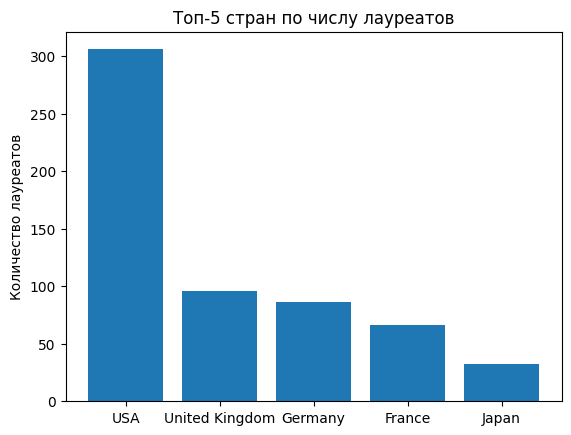

In [5]:
import matplotlib.pyplot as plt
from preparing_data.dataset_helpers import filter_records, group_by_attributes, apply_aggregation
from preparing_data.aggregations import count_records, mean_value, median_value, top_n

# убираю записи без страны, иначе None попадёт в рейтинг
with_country = filter_records(laureates_data, {'country_now': lambda value: value is not None})

# в тотале
counts_by_country = apply_aggregation(group_by_attributes(with_country, ['country_now']), count_records)
top_countries = top_n(counts_by_country, 5)
print(top_countries)

# по категориям: сначала группирую по категории, потом внутри каждой по стране
by_category = group_by_attributes(with_country, ['first_prize_category'])
for (category,), category_records in by_category.items():
    counts = apply_aggregation(group_by_attributes(category_records, ['country_now']), count_records)
    print(category, [(key[0], value) for key, value in top_n(counts, 5)])

# график
plt.bar([key[0] for key, _ in top_countries], [value for _, value in top_countries])
plt.title('Топ-5 стран по числу лауреатов')
plt.ylabel('Количество лауреатов')
plt.show()

Среднее: 60.6
Медиана: 61.0
Economic Sciences среднее: 67.2 медиана: 67
Physics среднее: 57.8 медиана: 56.0
Chemistry среднее: 59.4 медиана: 58
Literature среднее: 65.0 медиана: 67
Peace среднее: 61.0 медиана: 62.0
Physiology or Medicine среднее: 59.0 медиана: 58


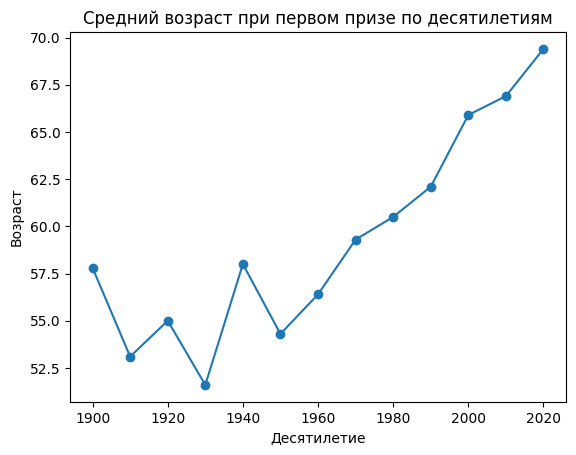

In [6]:
persons = filter_records(laureates_data, {'type_': 'person', 'age_at_first_prize': lambda age: age is not None})

print('Среднее:', round(mean_value(persons, 'age_at_first_prize'), 1))
print('Медиана:', median_value(persons, 'age_at_first_prize'))

by_category = group_by_attributes(persons, ['first_prize_category'])
mean_age = apply_aggregation(by_category, lambda recs: round(mean_value(recs, 'age_at_first_prize'), 1))
median_age = apply_aggregation(by_category, lambda recs: median_value(recs, 'age_at_first_prize'))

for key in mean_age:
    print(key[0], 'среднее:', mean_age[key], 'медиана:', median_age[key])

# динамика по десятилетиям
mean_age_by_decade = apply_aggregation(
    group_by_attributes(persons, ['first_prize_decade']),
    lambda recs: round(mean_value(recs, 'age_at_first_prize'), 1))
decades = sorted(mean_age_by_decade)

plt.plot([key[0] for key in decades], [mean_age_by_decade[key] for key in decades], marker='o')
plt.title('Средний возраст при первом призе по десятилетиям')
plt.xlabel('Десятилетие')
plt.ylabel('Возраст')
plt.show()

Всего женщин: 69
[(('Peace',), 21), (('Literature',), 19), (('Physiology or Medicine',), 14), (('Chemistry',), 7), (('Physics',), 5), (('Economic Sciences',), 3)]
[((2010, 'Peace'), 5), ((2020, 'Literature'), 4), ((2000, 'Physiology or Medicine'), 4), ((2020, 'Peace'), 4), ((2010, 'Literature'), 3)]


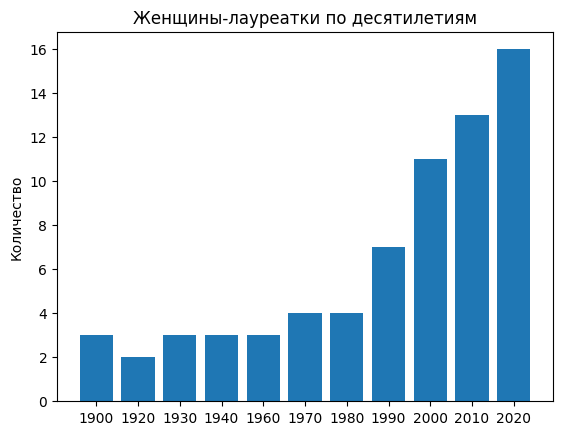

In [7]:
women = filter_records(laureates_data, {'gender': 'female'})
print('Всего женщин:', len(women))

# по десятилетиям
women_by_decade = apply_aggregation(group_by_attributes(women, ['first_prize_decade']), count_records)
decades = sorted(women_by_decade)

# по категориям (всего)
women_by_category = apply_aggregation(group_by_attributes(women, ['first_prize_category']), count_records)
print(top_n(women_by_category, 10))

# категория x десятилетие
women_by_both = apply_aggregation(
    group_by_attributes(women, ['first_prize_decade', 'first_prize_category']), count_records)
print(top_n(women_by_both, 5))

plt.bar([str(key[0]) for key in decades], [women_by_decade[key] for key in decades])
plt.title('Женщины-лауреатки по десятилетиям')
plt.ylabel('Количество')
plt.show()

## Общий анализ главы 2

В этой главе я исследовала три темы: **страны лауреатов**, **возраст при получении первой премии** и **женщин-лауреаток**. Для каждой темы я смотрела общие итоги, разбивку по категориям и динамику по десятилетиям. Для категорий и десятилетий я брала только **первый** приз лауреата, поэтому повторные премии сюда не вошли.

### 2.1. Топ стран по числу лауреатов

В тотале с большим отрывом лидируют **США (306)**. Дальше идут **Великобритания (96)**, **Германия (86)**, **Франция (66)** и **Япония (32)**. У США лауреатов в три раза больше, чем у второго места, то есть премии сильно сконцентрированы в нескольких странах.

По категориям картина похожая:
- В **Physiology or Medicine** (85), **Physics** (71), **Chemistry** (59) и **Economic Sciences** (56) США на первом месте. В экономике отрыв самый заметный: у ближайшей Великобритании только 7.
- В **Peace** тоже лидируют США (25), но отрыв небольшой: за ними Франция (12), Швейцария (8) и Великобритания (7).
- **Literature** единственная категория, где США не первые: там лидирует **Франция (12)**, США на втором месте (10), затем Швеция, Польша и Германия (по 7).
- Япония попала в топ-5 только в физике (12) и химии (9).

Страна бралась из поля `country_now` (страна на сегодняшний день), поэтому лауреат мог родиться или получить премию в другой стране.

### 2.2. Возраст при получении первой премии

Я рассматривала только людей. **Средний возраст** составил **60.6 года**, **медиана** — **61.0**. Они почти совпадают, поэтому, как я думаю, сильных выбросов в данных нет.

По категориям (среднее / медиана):
- **Economic Sciences:** 67.2 / 67, самые возрастные лауреаты.
- **Literature:** 65.0 / 67.
- **Peace:** 61.0 / 62.0.
- **Chemistry:** 59.4 / 58.
- **Physiology or Medicine:** 59.0 / 58.
- **Physics:** 57.8 / 56.0, самые молодые лауреаты.

Разница между экономикой и физикой почти **10 лет**. В литературе медиана выше среднего, и я предполагаю, что среднее занижают несколько молодых лауреатов. Динамику по десятилетиям смотрите на графике [опишите тренд: растёт или падает возраст].

### 2.3. Женщины-лауреатки

Всего среди лауреатов **69 женщин**. По категориям:
- **Peace:** 21
- **Literature:** 19
- **Physiology or Medicine:** 14
- **Chemistry:** 7
- **Physics:** 5
- **Economic Sciences:** 3

Больше всего женщин в гуманитарных категориях (мир и литература), а в естественных науках и экономике их заметно меньше. По десятилетиям самые большие значения приходятся на недавние годы: **2010-е** (мир, 5), **2020-е** (литература и мир, по 4) и **2000-е** (физиология и медицина, 4). Значит, число женщин-лауреаток со временем растёт, но 2020-е ещё не закончились, поэтому их цифры неполные.

### Главные выводы

- Премии сильно сконцентрированы в нескольких странах: **США** лидируют и в тотале, и почти во всех категориях, кроме литературы, где первая **Франция**.
- Лауреаты получают первую премию в среднем в **60-61 год**. Старше всех в экономике, моложе всех в физике.
- Женщин среди лауреатов мало (**69**), в основном в премии мира и литературе, но в последние десятилетия их становится больше.
- Ограничения анализа: я учитывала только первый приз лауреата, страну брала на сегодняшний день, а данные за 2020-е неполные.

---------

## Бонусное задание на +2 балла


### Лингвистический анализ мотиваций**

**5.1. Анализ текстов мотиваций**
- Соберите корпус текстов мотиваций вручения премий. Для этого измените конфиг обработки призов.
- Выделите самые частые топ-50 слов. Какие из этих слов самые частые в принципе в английском языке (такие, как for, the и другие), а какие кажутся важными именно в контексте вручения Нобелевской премии (например, 'chemistry')?
- Самые частые слова, которые также являются частыми во всем английском языке занесите в отдельный конфиг-файл под названием `stopwords.py`. Вычистите их из текстов. Какие слова являются самыми частыми теперь? Сравните множества топ-10 самых частых слов по разным категориям


- Если есть желание, посчитайте TF-IDF + сравнените топ слов по этой метрике с просто самыми популярными словами)